# 🏠 Housing Price Estimation — Machine Learning Project

**Goal:** US ke economic indicators (mortgage rate, interest rate, CPI, GDP, unemployment, population growth) use karke **Home Price Index (Case-Shiller)** ko estimate karna.

**Data source:** FRED (Federal Reserve Economic Data), 7 CSV files.

**Project ke steps:**
1. Libraries import karna
2. Data load karna
3. Alag-alag frequency ka data monthly me convert karke merge karna
4. EDA (data ko samajhna aur graphs)
5. **Model 1:** Seedha HPI predict karna (aur dekhna ki kyun problem aati hai)
6. **Model 2:** Better target — YoY growth predict karna (sirf macro features)
7. **Model 3:** Past HPI momentum jodkar final model
8. Models ki comparison, feature importance
9. What-if prediction aur model save karna
10. Conclusion

> ⚠️ Ye model **poore US ka housing price index** predict karta hai, kisi ek ghar ka price nahi.

## Step 1: Libraries import karo

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 4)

## Step 2: Data load karo

Saari CSV files notebook wale folder me honi chahiye. `parse_dates` se `DATE` asli date ban jaati hai aur `index_col` se wo row ki pehchaan (index) ban jaati hai.

In [2]:
def load(file):
    return pd.read_csv(file, parse_dates=["DATE"], index_col="DATE")

hpi   = load("Home-Price-Index.csv")        # target (monthly)
cpi   = load("Consumer-Price-Index.csv")    # monthly
fed   = load("FedFunds.csv")                # monthly
unemp = load("Unemployment-Rate.csv")       # monthly
mort  = load("Mortgage.csv")                # WEEKLY
gdp   = load("GDP.csv")                     # QUARTERLY
pop   = load("Population-Growth.csv")       # YEARLY

for name, d in [("HPI", hpi), ("CPI", cpi), ("FedFunds", fed), ("Unemployment", unemp),
                ("Mortgage", mort), ("GDP", gdp), ("Population", pop)]:
    print(f"{name:13s} rows={len(d):5d}  {d.index.min().date()} -> {d.index.max().date()}")

HPI           rows=  439  1987-01-01 -> 2023-07-01
CPI           rows=  921  1947-01-01 -> 2023-09-01
FedFunds      rows=  831  1954-07-01 -> 2023-09-01
Unemployment  rows=  909  1948-01-01 -> 2023-09-01
Mortgage      rows= 2744  1971-04-02 -> 2023-10-26
GDP           rows=  307  1947-01-01 -> 2023-07-01
Population    rows=   62  1961-01-01 -> 2022-01-01


## Step 3: Sabko monthly frequency me laao aur merge karo

Files ki frequency alag hai, isliye:
- **Mortgage (weekly)** → mahine ka average
- **GDP (quarterly)** → quarter ki value us quarter ke har mahine me
- **Population growth (yearly)** → saal ki value us saal ke har mahine me

In [3]:
mort_m = mort.resample("MS").mean()     # weekly -> monthly average
gdp_m  = gdp.resample("MS").ffill()     # quarterly -> monthly
pop_m  = pop.resample("MS").ffill()     # yearly -> monthly

df = pd.concat([hpi, cpi, fed, unemp, mort_m, gdp_m, pop_m], axis=1, sort=True)
df.columns = ["HPI", "CPI", "FedFunds", "Unemployment", "Mortgage", "GDP", "PopGrowth"]

df = df.ffill()                                   # end ke gaps (e.g. population) bharo
df = df.loc[hpi.index.min():hpi.index.max()]      # HPI ki date range tak rakho
df = df.dropna()

print("Shape:", df.shape)
df.head()

Shape: (439, 7)


,HPI,CPI,FedFunds,Unemployment,Mortgage,GDP,PopGrowth
DATE,,,,,,,
1987-01-01,63.964,111.4,6.43,6.6,9.2040,4722.156,0.893829
1987-02-01,64.424,111.8,6.10,6.6,9.0825,4722.156,0.893829
1987-03-01,64.736,112.2,6.13,6.6,9.0350,4722.156,0.893829
1987-04-01,65.132,112.7,6.37,6.3,9.8325,4806.160,0.893829
1987-05-01,65.563,113.0,6.85,6.3,10.5960,4806.160,0.893829


In [4]:
df.tail()

,HPI,CPI,FedFunds,Unemployment,Mortgage,GDP,PopGrowth
DATE,,,,,,,
2023-03-01,298.396,301.808,4.65,3.5,6.5440,26813.601,0.377565
2023-04-01,300.208,302.918,4.83,3.4,6.3425,27063.012,0.377565
2023-05-01,302.685,303.294,5.06,3.7,6.4250,27063.012,0.377565
2023-06-01,304.741,303.841,5.08,3.6,6.7140,27063.012,0.377565
2023-07-01,306.720,304.348,5.12,3.5,6.8400,27623.543,0.377565


## Step 4: EDA — data ko samjho

In [5]:
print(df.info())
print("\nMissing values:\n", df.isna().sum())
df.describe().round(2)

<class 'pandas.DataFrame'>
DatetimeIndex: 439 entries, 1987-01-01 to 2023-07-01
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   HPI           439 non-null    float64
 1   CPI           439 non-null    float64
 2   FedFunds      439 non-null    float64
 3   Unemployment  439 non-null    float64
 4   Mortgage      439 non-null    float64
 5   GDP           439 non-null    float64
 6   PopGrowth     439 non-null    float64
dtypes: float64(7)
memory usage: 27.4 KB
None

Missing values:
 HPI             0
CPI             0
FedFunds        0
Unemployment    0
Mortgage        0
GDP             0
PopGrowth       0
dtype: int64


,HPI,CPI,FedFunds,Unemployment,Mortgage,GDP,PopGrowth
count,439.00,439.00,439.00,439.00,439.00,439.00,439.00
mean,141.14,195.75,3.16,5.78,6.32,13236.39,0.90
std,60.26,48.71,2.68,1.68,2.17,5902.26,0.28
min,63.96,111.40,0.05,3.40,2.68,4722.16,0.16
25%,82.07,155.25,0.34,4.60,4.32,7868.47,0.73
50%,140.35,193.60,2.96,5.40,6.26,12922.66,0.93
75%,178.14,236.00,5.30,6.60,7.84,17518.51,1.13
max,306.72,304.35,9.85,14.70,11.26,27623.54,1.39


### 4.1 Home Price Index time ke saath

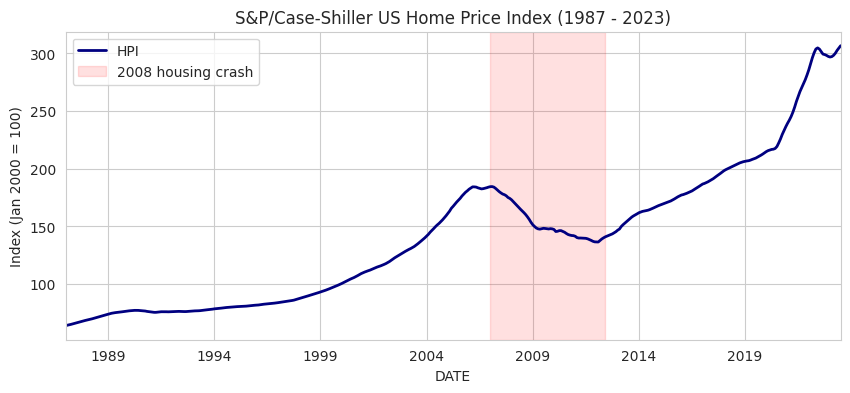

In [6]:
ax = df["HPI"].plot(color="navy", linewidth=2)
ax.set_title("S&P/Case-Shiller US Home Price Index (1987 - 2023)")
ax.set_ylabel("Index (Jan 2000 = 100)")
# 2008 crisis ka area mark karo
ax.axvspan(pd.Timestamp("2007-01-01"), pd.Timestamp("2012-06-01"), color="red", alpha=0.12, label="2008 housing crash")
ax.legend()
plt.show()

### 4.2 Saare features ek saath

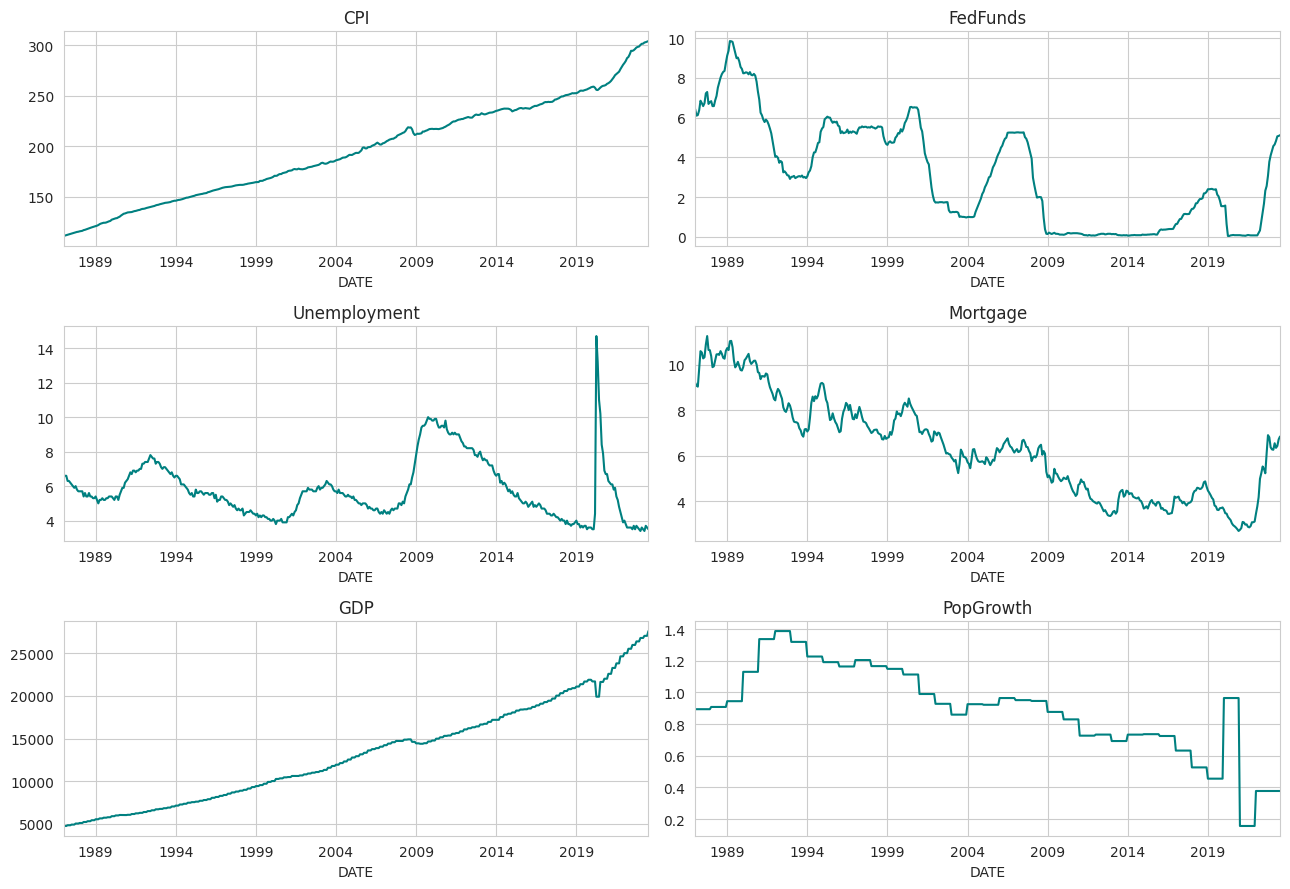

In [7]:
fig, axes = plt.subplots(3, 2, figsize=(13, 9))
for ax, col in zip(axes.ravel(), ["CPI", "FedFunds", "Unemployment", "Mortgage", "GDP", "PopGrowth"]):
    df[col].plot(ax=ax, color="teal")
    ax.set_title(col)
plt.tight_layout()
plt.show()

### 4.3 Correlation heatmap

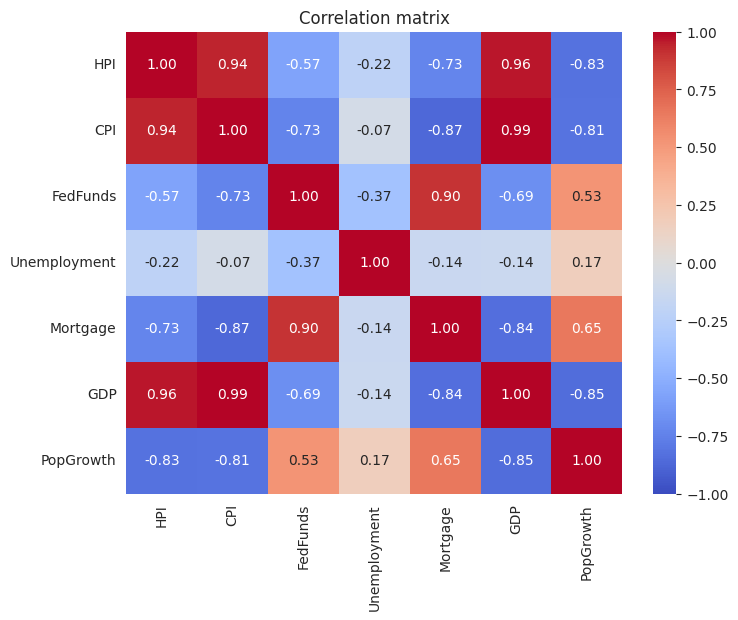

In [8]:
plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Correlation matrix")
plt.show()

**Observation:** HPI, CPI aur GDP ka correlation bahut high hai kyunki ye teeno time ke saath badhte hain (trend). Ye ek **spurious correlation** ho sakta hai — sirf trend ki wajah se numbers saath chalte dikhte hain, zaroori nahi ki ek doosre ko cause kar rahe hon. Isi wajah se hum aage growth rates (percent change) bhi use karenge.

## Step 5: Model 1 — Seedha HPI (level) predict karo

Pehle sabse simple approach: features se seedha HPI ki value predict karo.

**Important:** Ye time series data hai, isliye **random split nahi**. Purane 80% data pe train aur naye 20% pe test, warna model future ki jaankari "chura" leta hai.

In [9]:
X = df.drop(columns="HPI")
y = df["HPI"]

split = int(len(df) * 0.8)
X_train, X_test = X.iloc[:split], X.iloc[split:]
y_train, y_test = y.iloc[:split], y.iloc[split:]

print("Train:", X_train.index.min().date(), "->", X_train.index.max().date(), f"({len(X_train)} rows)")
print("Test :", X_test.index.min().date(),  "->", X_test.index.max().date(),  f"({len(X_test)} rows)")

Train: 1987-01-01 -> 2016-03-01 (351 rows)
Test : 2016-04-01 -> 2023-07-01 (88 rows)


In [10]:
def metrics(y_true, y_pred):
    return {
        "MAE":  mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2":   r2_score(y_true, y_pred),
    }

results = {}   # saare models ka result yahan jama karenge

models1 = {
    "Linear Regression": make_pipeline(StandardScaler(), LinearRegression()),
    "Random Forest":     RandomForestRegressor(n_estimators=300, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
}

preds1 = {}
for name, m in models1.items():
    m.fit(X_train, y_train)
    preds1[name] = m.predict(X_test)
    results[f"M1 {name}"] = metrics(y_test, preds1[name])

pd.DataFrame(results).T.round(3)

,MAE,RMSE,R2
M1 Linear Regression,18.412,20.580,0.766
M1 Random Forest,56.673,71.219,-1.801
M1 Gradient Boosting,56.232,70.390,-1.736


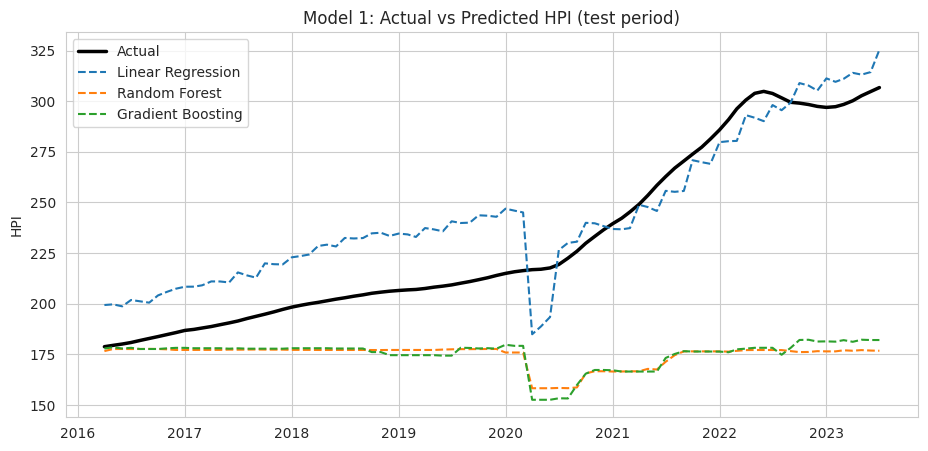

In [11]:
plt.figure(figsize=(11, 5))
plt.plot(y_test.index, y_test, label="Actual", color="black", linewidth=2.5)
for name, p in preds1.items():
    plt.plot(y_test.index, p, label=name, linestyle="--")
plt.title("Model 1: Actual vs Predicted HPI (test period)")
plt.ylabel("HPI"); plt.legend()
plt.show()

### 🔍 Observation (bahut important)

**Random Forest aur Gradient Boosting ka R² negative hai** — matlab wo ek seedhi line (average) se bhi kharab hain. Graph me dekho: unki predictions ek jagah **flat** ho jaati hain.

**Wajah:** Tree-based models un values ko predict nahi kar sakte jo unhone training me kabhi dekhi hi nahi. Test period me HPI (~200-300) training ke maximum (~185) se upar chala gaya, to trees "extrapolate" nahi kar paate. Linear Regression trend pakad leta hai isliye thoda behtar hai.

**Solution:** HPI ki jagah uski **growth rate** predict karo, jo stable range me rehti hai. Ye hum Model 2 me karenge.

## Step 6: Feature Engineering

Ab hum levels ki jagah **changes / growth rates** use karenge:
- `CPI_yoy`, `GDP_yoy`: pichle saal se % change (inflation, economy growth)
- `Mortgage_chg12`, `Unemp_chg12`: pichle saal se change
- Lagged features: 6 mahine pehle ka mortgage/fed rate (rates ka asar ghar ke daam par der se aata hai)

**Naya target:** `HPI_yoy` = HPI me pichle 12 mahine me % change.

In [12]:
F = pd.DataFrame(index=df.index)

# --- Macro features ---
F["CPI_yoy"]        = df["CPI"].pct_change(12) * 100
F["GDP_yoy"]        = df["GDP"].pct_change(12) * 100
F["FedFunds"]       = df["FedFunds"]
F["Unemployment"]   = df["Unemployment"]
F["Mortgage"]       = df["Mortgage"]
F["PopGrowth"]      = df["PopGrowth"]
F["Mortgage_chg12"] = df["Mortgage"].diff(12)
F["Unemp_chg12"]    = df["Unemployment"].diff(12)
F["Mortgage_lag6"]  = df["Mortgage"].shift(6)
F["FedFunds_lag6"]  = df["FedFunds"].shift(6)

macro_cols = list(F.columns)

# --- Past HPI momentum (Model 3 ke liye) ---
hpi_yoy = df["HPI"].pct_change(12) * 100
F["HPI_yoy_lag1"]  = hpi_yoy.shift(1)     # pichle mahine ki growth
F["HPI_yoy_lag12"] = hpi_yoy.shift(12)    # 1 saal pehle ki growth

# --- Target aur reconstruction ke liye helper columns ---
D = F.copy()
D["target_yoy"] = hpi_yoy                 # kya predict karna hai
D["HPI"]        = df["HPI"]               # asli HPI (comparison ke liye)
D["HPI_prev12"] = df["HPI"].shift(12)     # 12 mahine pehle ka HPI (wapas HPI banane ke liye)
D = D.dropna()

print("Rows after feature engineering:", len(D))
D.head()

Rows after feature engineering: 415


,CPI_yoy,GDP_yoy,FedFunds,Unemployment,Mortgage,PopGrowth,Mortgage_chg12,Unemp_chg12,Mortgage_lag6,FedFunds_lag6,HPI_yoy_lag1,HPI_yoy_lag12,target_yoy,HPI,HPI_prev12
DATE,,,,,,,,,,,,,,,
1989-01-01,4.482759,8.630966,9.12,5.4,10.7300,0.944406,0.3475,-0.3,10.4320,7.75,7.240242,7.651179,7.389120,73.946,68.858
1989-02-01,4.647160,8.630966,9.36,5.2,10.6450,0.944406,0.7525,-0.5,10.5975,8.01,7.389120,7.511176,7.390670,74.382,69.263
1989-03-01,4.892704,8.630966,9.85,5.0,11.0320,0.944406,1.1020,-0.7,10.4800,8.19,7.390670,7.575383,7.377944,74.778,69.640
1989-04-01,5.034130,8.139192,9.84,5.2,11.0500,0.944406,0.8480,-0.2,10.3025,8.30,7.377944,7.438740,7.300970,75.086,69.977
1989-05-01,5.276596,8.139192,9.81,5.2,10.7725,0.944406,0.3175,-0.4,10.2650,8.35,7.300970,7.417293,6.929259,75.306,70.426


Train: 1989-01-01 -> 2016-08-01 (332 rows)
Test : 2016-09-01 -> 2023-07-01 (83 rows)


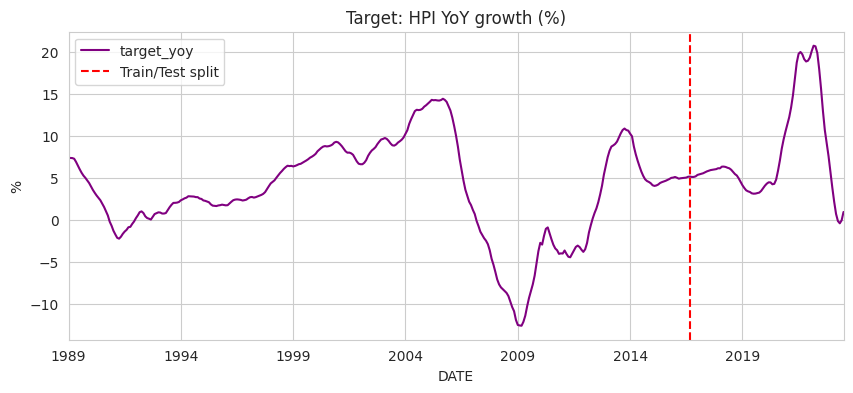

In [13]:
split = int(len(D) * 0.8)
train, test = D.iloc[:split], D.iloc[split:]
print("Train:", train.index.min().date(), "->", train.index.max().date(), f"({len(train)} rows)")
print("Test :", test.index.min().date(),  "->", test.index.max().date(),  f"({len(test)} rows)")

plt.figure()
D["target_yoy"].plot(color="purple")
plt.axvline(test.index.min(), color="red", linestyle="--", label="Train/Test split")
plt.title("Target: HPI YoY growth (%)"); plt.ylabel("%"); plt.legend()
plt.show()

Dekho, growth rate ek stable range (lagbhag -13% se +21%) me ghoomta hai — trees ke liye ye ideal hai.

**Predicted growth se wapas HPI kaise banayenge?**
`HPI_predicted = HPI_(12 mahine pehle) × (1 + predicted_growth / 100)`
Pichle saal ka HPI humein pata hota hai, isliye ye valid hai.

## Step 7: Model 2 — Sirf macro features se YoY growth predict karo

In [14]:
def fit_eval(model, cols, label):
    model.fit(train[cols], train["target_yoy"])
    p_yoy = model.predict(test[cols])
    p_hpi = test["HPI_prev12"] * (1 + p_yoy / 100)       # growth -> HPI
    r = metrics(test["HPI"], p_hpi)
    r["YoY_MAE(%)"] = mean_absolute_error(test["target_yoy"], p_yoy)
    results[label] = r
    return model, p_hpi

models2 = {
    "Ridge":             make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    "Random Forest":     RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
}

fitted2, preds2 = {}, {}
for name, m in models2.items():
    fitted2[name], preds2[name] = fit_eval(m, macro_cols, f"M2 {name}")

pd.DataFrame(results).T.loc[[k for k in results if k.startswith("M2")]].round(3)

,MAE,RMSE,R2,YoY_MAE(%)
M2 Ridge,18.440,24.536,0.657,8.218
M2 Random Forest,12.303,15.313,0.866,5.400
M2 Gradient Boosting,12.561,15.472,0.863,5.492


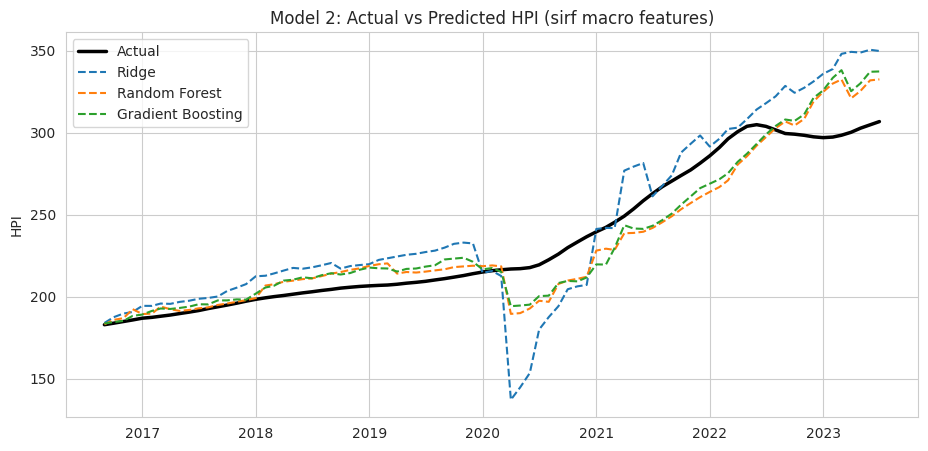

In [15]:
plt.figure(figsize=(11, 5))
plt.plot(test.index, test["HPI"], label="Actual", color="black", linewidth=2.5)
for name, p in preds2.items():
    plt.plot(test.index, p, label=name, linestyle="--")
plt.title("Model 2: Actual vs Predicted HPI (sirf macro features)")
plt.ylabel("HPI"); plt.legend()
plt.show()

### 🔍 Observation
Model 1 ke muqable **bahut behtar** — Random Forest ka R² ab ~0.87 hai (pehle negative tha) aur MAE 56 se ghatkar ~12 index points reh gaya. Matlab sirf macro indicators se hi HPI ka kaafi hissa explain ho jaata hai. Lekin error abhi bhi kaafi hai, kyunki housing prices me **momentum** hota hai — jo macro data me nahi hota. Ye bhi dekho ki yahan Ridge (linear) sabse kharab hai aur trees jeet rahe hain — Model 3 me ulta hoga.

### Feature importance (Model 2 — Random Forest)
Kaun sa feature growth predict karne me sabse zyada kaam aa raha hai?

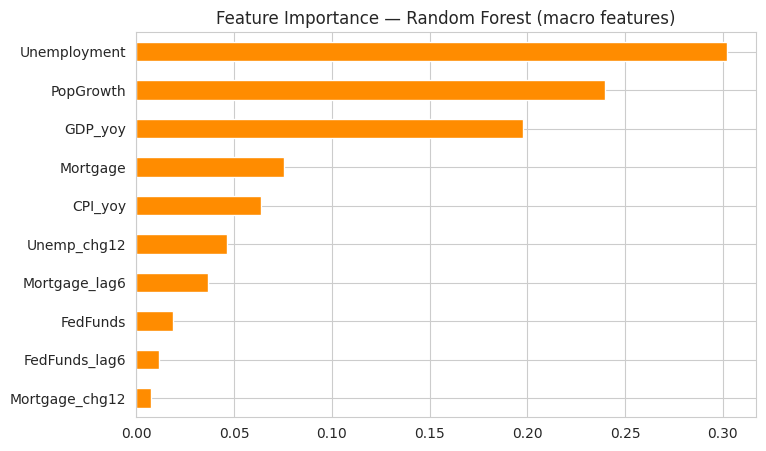

In [16]:
imp = pd.Series(fitted2["Random Forest"].feature_importances_, index=macro_cols).sort_values()
imp.plot(kind="barh", color="darkorange", figsize=(8, 5))
plt.title("Feature Importance — Random Forest (macro features)")
plt.show()

## Step 8: Model 3 — Past HPI momentum jodkar final model

Ghar ke daam achanak nahi badalte, ek trend me chalte hain. Isliye pichle mahine ki aur 1 saal pehle ki HPI growth bhi features me jodte hain.

> **Note:** Ye model is sense me "forecast" jaisa hai ki ise pichle mahine tak ka HPI pata hona chahiye. Model 2 sirf macro data se estimate karta hai; Model 3 recent HPI trend + macro data dono use karta hai.

In [17]:
all_cols = macro_cols + ["HPI_yoy_lag1", "HPI_yoy_lag12"]

models3 = {
    "Ridge":             make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    "Random Forest":     RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
}

fitted3, preds3 = {}, {}
for name, m in models3.items():
    fitted3[name], preds3[name] = fit_eval(m, all_cols, f"M3 {name}")

# Baseline: "pichle mahine ki growth hi dobara chalegi"
naive = test["HPI_prev12"] * (1 + test["HPI_yoy_lag1"] / 100)
r = metrics(test["HPI"], naive)
r["YoY_MAE(%)"] = mean_absolute_error(test["target_yoy"], test["HPI_yoy_lag1"])
results["Baseline (naive)"] = r

pd.DataFrame(results).T.loc[[k for k in results if k.startswith("M3") or k.startswith("Base")]].round(3)

,MAE,RMSE,R2,YoY_MAE(%)
M3 Ridge,1.085,1.679,0.998,0.451
M3 Random Forest,3.124,5.464,0.983,1.318
M3 Gradient Boosting,3.270,5.832,0.981,1.382
Baseline (naive),1.390,2.240,0.997,0.571


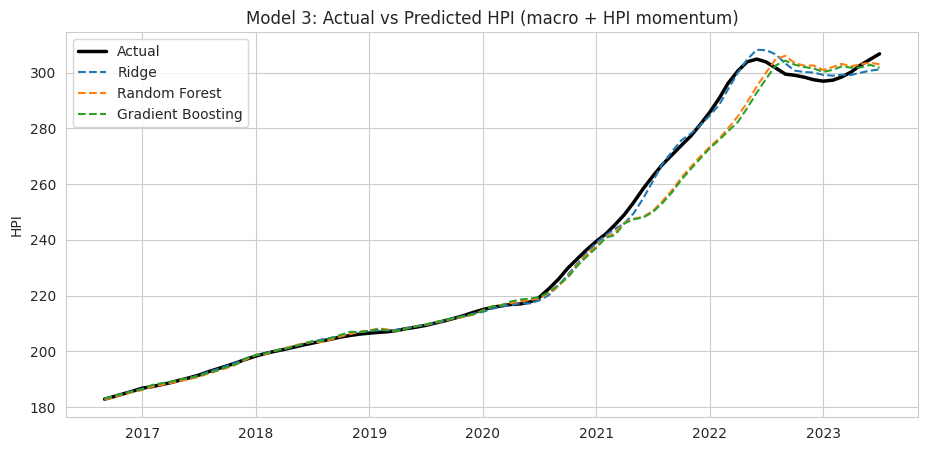

In [18]:
plt.figure(figsize=(11, 5))
plt.plot(test.index, test["HPI"], label="Actual", color="black", linewidth=2.5)
for name, p in preds3.items():
    plt.plot(test.index, p, label=name, linestyle="--")
plt.title("Model 3: Actual vs Predicted HPI (macro + HPI momentum)")
plt.ylabel("HPI"); plt.legend()
plt.show()

### 🔍 Observation
Model 3 me **Ridge Regression** sabse accha nikla: R² ≈ 0.998 aur MAE ≈ 1.1 index point. Ye naive baseline (MAE ≈ 1.4) ko bhi hara deta hai, lekin **sirf thode se margin se**. Sach ye hai ki is model ki zyadatar taakat past HPI momentum se aa rahi hai; macro features thoda sa extra sudhaar dete hain.

Aur ek dilchasp baat: simple Ridge, Random Forest se behtar hai. Isse pata chalta hai ki **zyada complex model hamesha behtar nahi hota** — jab relationship lagbhag linear ho, simple model jeet jaata hai.

## Step 9: Saare models ki final comparison

,MAE,RMSE,R2,YoY_MAE(%)
M3 Ridge,1.085,1.679,0.998,0.451
Baseline (naive),1.390,2.240,0.997,0.571
M3 Random Forest,3.124,5.464,0.983,1.318
M3 Gradient Boosting,3.270,5.832,0.981,1.382
M2 Random Forest,12.303,15.313,0.866,5.400
M2 Gradient Boosting,12.561,15.472,0.863,5.492
M1 Linear Regression,18.412,20.580,0.766,NaN
M2 Ridge,18.440,24.536,0.657,8.218
M1 Gradient Boosting,56.232,70.390,-1.736,NaN
M1 Random Forest,56.673,71.219,-1.801,NaN


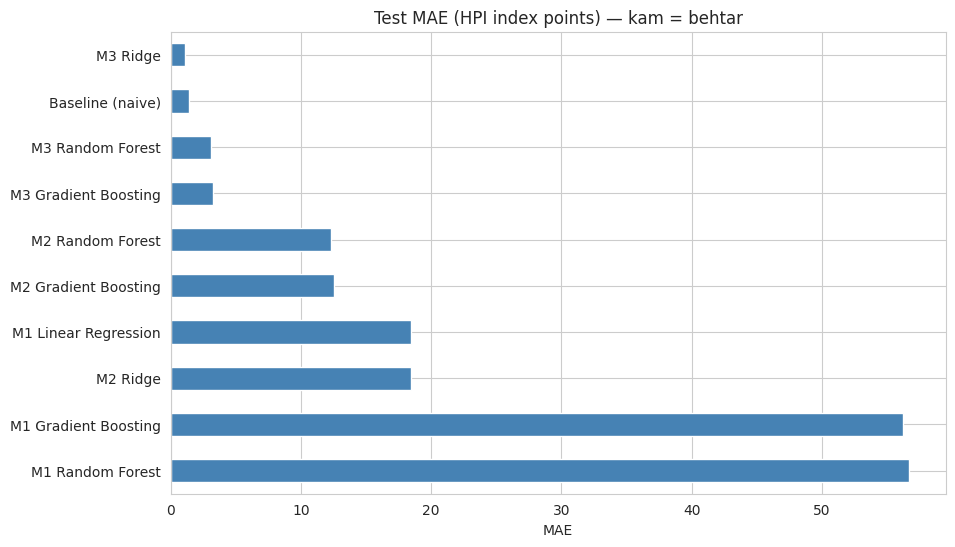

In [19]:
summary = pd.DataFrame(results).T.round(3)
summary["Stage"] = summary.index.str.extract(r"^(M\d|Baseline)")[0].values
summary = summary.sort_values("MAE")
display(summary[["MAE", "RMSE", "R2", "YoY_MAE(%)"]])

plt.figure(figsize=(10, 6))
summary["MAE"].sort_values(ascending=False).plot(kind="barh", color="steelblue")
plt.title("Test MAE (HPI index points) — kam = behtar")
plt.xlabel("MAE")
plt.show()

### Final model ki coefficients (kaun sa feature kis direction me asar daal raha hai)

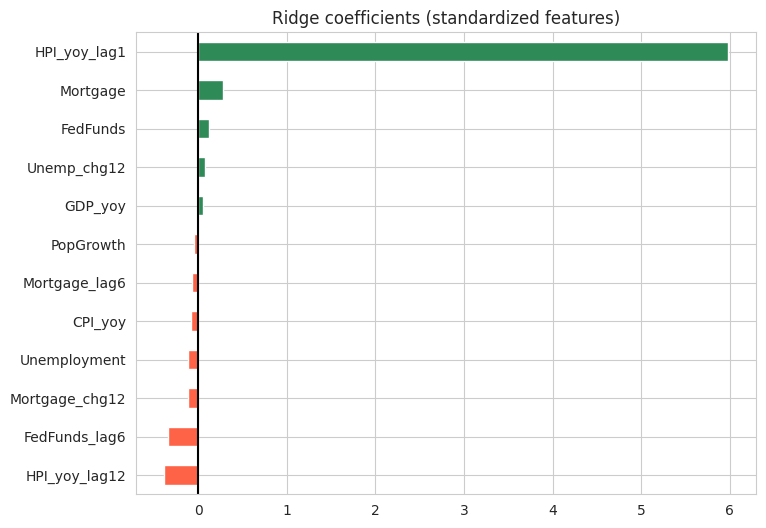

In [20]:
best = fitted3["Ridge"]
coefs = pd.Series(best.named_steps["ridge"].coef_, index=all_cols).sort_values()
coefs.plot(kind="barh", color=["tomato" if c < 0 else "seagreen" for c in coefs], figsize=(8, 6))
plt.title("Ridge coefficients (standardized features)")
plt.axvline(0, color="black")
plt.show()

## Step 10: What-if prediction + model save

Final model (Model 3 Ridge) se ek prediction karte hain: *agar mortgage rate 1% badh jaye to?*

In [21]:
# Test period ki aakhri row ko base maano
base_row = test.iloc[[-1]][all_cols].copy()
prev12   = test["HPI_prev12"].iloc[-1]
actual   = test["HPI"].iloc[-1]

def predict_hpi(row):
    yoy = best.predict(row)[0]
    return prev12 * (1 + yoy / 100), yoy

p_base, yoy_base = predict_hpi(base_row)
print(f"Date: {base_row.index[0].date()}")
print(f"Actual HPI    : {actual:.2f}")
print(f"Predicted HPI : {p_base:.2f}   (YoY growth {yoy_base:.2f}%)")

# What-if: mortgage rate +1%
whatif = base_row.copy()
whatif["Mortgage"]       += 1.0
whatif["Mortgage_chg12"] += 1.0
p_w, yoy_w = predict_hpi(whatif)
print(f"\nAgar mortgage rate +1% hota -> Predicted HPI: {p_w:.2f}  (YoY growth {yoy_w:.2f}%)")

Date: 2023-07-01
Actual HPI    : 306.72
Predicted HPI : 301.15   (YoY growth -0.87%)

Agar mortgage rate +1% hota -> Predicted HPI: 301.09  (YoY growth -0.89%)


**Dhyan do:** Mortgage +1% karne se prediction me bahut kam farak aaya. Ye model ab zyadatar pichle HPI momentum par depend karta hai, isliye ek akele feature ka asar chhota dikhta hai. Real life me mortgage rate ka asar ghar ke daamon par dheere-dheere (kai mahino me) aata hai. Is what-if ko "exact forecast" nahi, balki sirf ek demo samjho.

In [22]:
joblib.dump({"model": best, "features": all_cols}, "housing_price_model.pkl")
print("Model save ho gaya: housing_price_model.pkl")

# Baad me load karne ke liye:
# saved = joblib.load("housing_price_model.pkl")
# saved["model"].predict(new_data[saved["features"]])

Model save ho gaya: housing_price_model.pkl


## Step 11: Conclusion

**Kya seekha:**
1. **Time series ko random split mat karo** — hamesha purana data train, naya data test.
2. **Trending data pe tree models fail hote hain** (Model 1: negative R²). Levels ki jagah growth rates predict karo.
3. **Feature engineering model se zyada important hai** — growth rates, differences aur lags se result drastically behtar hua.
4. **Simple model kabhi-kabhi complex ko hara deta hai** — Ridge ne Random Forest aur Gradient Boosting ko beat kiya.
5. **Baseline zaroor banao** — naive baseline ke bina pata nahi chalta ki model sach me kuch seekh raha hai ya nahi.

**Final results (test set):**

| Approach | Features | Best Model | R² (HPI) |
|---|---|---|---|
| Model 1 | Macro levels | Linear Regression | ~0.77 |
| Model 2 | Macro growth/lags | Random Forest | ~0.87 |
| Model 3 | Macro + HPI momentum | **Ridge** | **~0.998** (naive baseline: ~0.997) |

**Limitations:**
- Ye poore US ka national index hai, individual ghar ka price nahi.
- Test period (2016-2023) me COVID jaise unusual events hain, jinhe koi model aasaani se predict nahi kar sakta.
- Model 3 ko pichle mahine tak ka HPI chahiye (forecast-type model).
- Sirf ~430 monthly rows hain, data kam hai.

**Aage kya kar sakte ho:**
- `TimeSeriesSplit` se cross-validation
- Hyperparameter tuning (`GridSearchCV`)
- State-level ya city-level housing data jodna
- XGBoost / LightGBM, ya ARIMA / Prophet jaise time-series models
- Streamlit app banake model deploy karna